# Statistics for Data Science with Python — Final Project

**Author:** Nguyễn Hùng

Project scenario: as a Data Scientist working for a housing agency in Boston, I use the Boston Housing dataset to answer questions from upper management with descriptive statistics, visualizations and hypothesis tests.

## Task 1: Become familiar with the dataset

The dataset contains information about houses in Boston suburbs:

- **CRIM** — per capita crime rate by town
- **ZN** — proportion of residential land zoned for lots over 25,000 sq.ft.
- **INDUS** — proportion of non-retail business acres per town
- **CHAS** — Charles River dummy variable (1 if tract bounds river; 0 otherwise)
- **NOX** — nitric oxides concentration (parts per 10 million)
- **RM** — average number of rooms per dwelling
- **AGE** — proportion of owner-occupied units built prior to 1940
- **DIS** — weighted distances to five Boston employment centres
- **RAD** — index of accessibility to radial highways
- **TAX** — full-value property-tax rate per $10,000
- **PTRATIO** — pupil-teacher ratio by town
- **LSTAT** — % lower status of the population
- **MEDV** — median value of owner-occupied homes in $1000's

## Task 2: Load the dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
print("Libraries imported successfully")

Libraries imported successfully


In [2]:
boston_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv"
boston_df = pd.read_csv(boston_url)
boston_df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,5.33,36.2


In [3]:
boston_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  506 non-null    int64  
 1   CRIM        506 non-null    float64
 2   ZN          506 non-null    float64
 3   INDUS       506 non-null    float64
 4   CHAS        506 non-null    float64
 5   NOX         506 non-null    float64
 6   RM          506 non-null    float64
 7   AGE         506 non-null    float64
 8   DIS         506 non-null    float64
 9   RAD         506 non-null    float64
 10  TAX         506 non-null    float64
 11  PTRATIO     506 non-null    float64
 12  LSTAT       506 non-null    float64
 13  MEDV        506 non-null    float64
dtypes: float64(13), int64(1)
memory usage: 55.5 KB


In [4]:
boston_df.describe()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


## Task 3: Descriptive statistics and visualizations

### 3.1 Boxplot for the Median value of owner-occupied homes (MEDV)

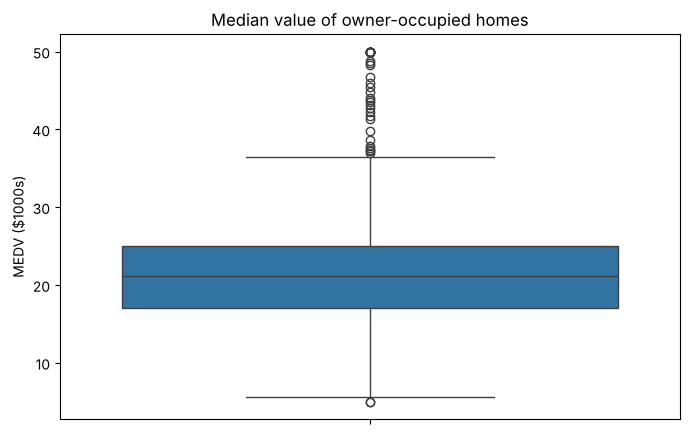

In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(y=boston_df['MEDV'])
plt.title('Median value of owner-occupied homes')
plt.ylabel('MEDV ($1000s)')
plt.show()

**Explanation:** Most homes have a median value between about \$17,000 and \$25,000. There are many outliers above about \$37,000, so the distribution is skewed toward higher values.

### 3.2 Bar plot for the Charles River variable (CHAS)

/tmp/ipykernel_302/583944913.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Not bounded (0)', 'Bounded (1)'])


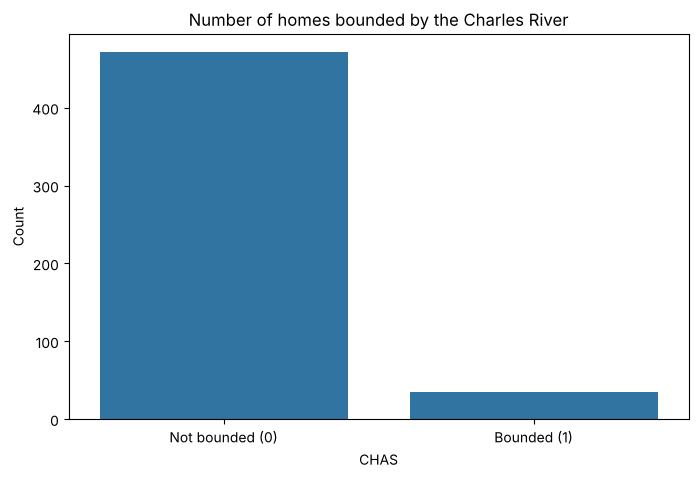

In [6]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(x='CHAS', data=boston_df)
ax.set_xticklabels(['Not bounded (0)', 'Bounded (1)'])
plt.title('Number of homes bounded by the Charles River')
plt.xlabel('CHAS')
plt.ylabel('Count')
plt.show()

In [7]:
boston_df['CHAS'].value_counts()

CHAS
0.0    471
1.0     35
Name: count, dtype: int64

**Explanation:** The vast majority of tracts (471) are not bounded by the Charles River; only 35 are.

### 3.3 Boxplot of MEDV vs AGE groups

AGE is discretized into three groups: 35 years and younger, between 35 and 70 years, and 70 years and older.

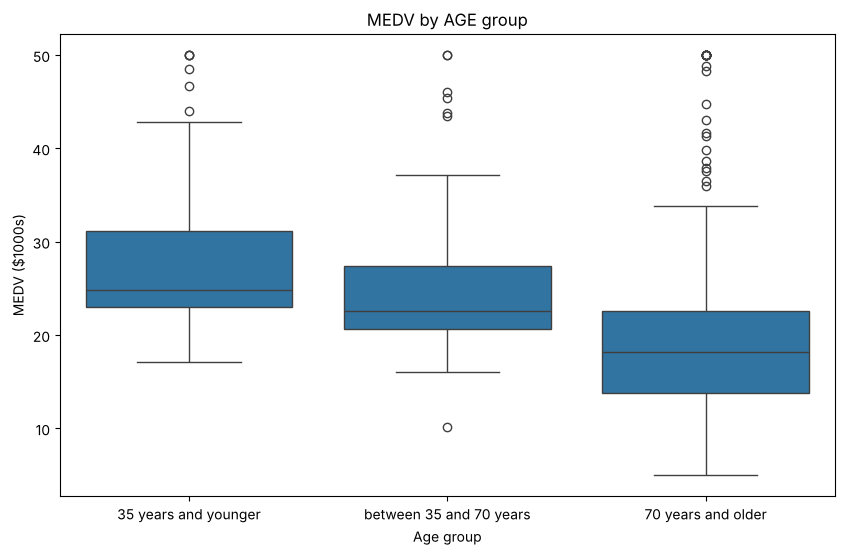

In [8]:
boston_df.loc[boston_df['AGE'] <= 35, 'age_group'] = '35 years and younger'
boston_df.loc[(boston_df['AGE'] > 35) & (boston_df['AGE'] < 70), 'age_group'] = 'between 35 and 70 years'
boston_df.loc[boston_df['AGE'] >= 70, 'age_group'] = '70 years and older'

plt.figure(figsize=(10, 6))
sns.boxplot(x='age_group', y='MEDV', data=boston_df,
            order=['35 years and younger', 'between 35 and 70 years', '70 years and older'])
plt.title('MEDV by AGE group')
plt.xlabel('Age group')
plt.ylabel('MEDV ($1000s)')
plt.show()

**Explanation:** Towns with a higher proportion of older homes (70 years and older) tend to have a lower median home value than the other two groups.

### 3.4 Scatter plot of NOX vs INDUS

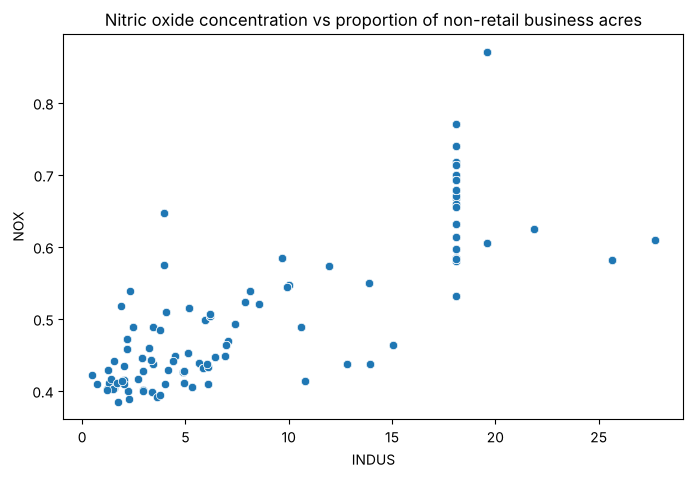

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(x='INDUS', y='NOX', data=boston_df)
plt.title('Nitric oxide concentration vs proportion of non-retail business acres')
plt.xlabel('INDUS')
plt.ylabel('NOX')
plt.show()

**Explanation:** There is a positive relationship: towns with a larger proportion of non-retail business acres tend to have higher nitric oxide concentrations.

### 3.5 Histogram for the pupil to teacher ratio (PTRATIO)

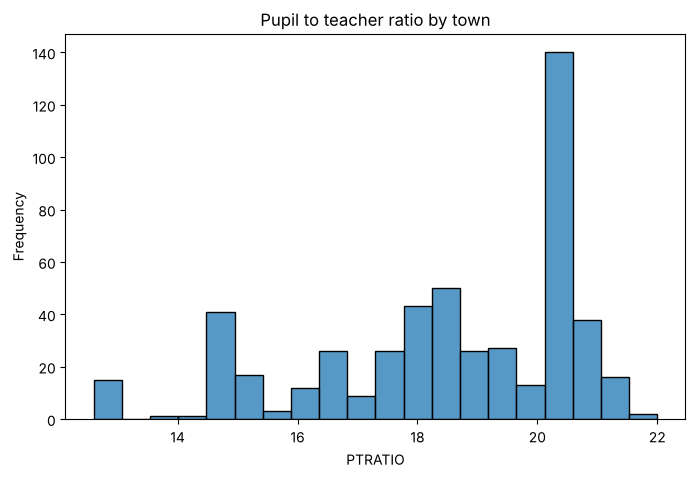

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(boston_df['PTRATIO'], bins=20, kde=False)
plt.title('Pupil to teacher ratio by town')
plt.xlabel('PTRATIO')
plt.ylabel('Frequency')
plt.show()

**Explanation:** The distribution is left-skewed; many towns have a pupil-teacher ratio around 20 to 21.

## Task 4: Statistical tests

For all tests, α = 0.05.

### 4.1 Is there a significant difference in median value of houses bounded by the Charles River or not? (T-test for independent samples)

- **H₀:** µ₁ = µ₂ (there is no difference in median value between houses bounded and not bounded by the Charles River)
- **H₁:** µ₁ ≠ µ₂ (there is a difference)

In [11]:
# Check equality of variances first
scipy.stats.levene(boston_df[boston_df['CHAS'] == 0]['MEDV'],
                   boston_df[boston_df['CHAS'] == 1]['MEDV'], center='mean')

LeveneResult(statistic=np.float64(8.75190489604598), pvalue=np.float64(0.0032381193676394252))

In [12]:
scipy.stats.ttest_ind(boston_df[boston_df['CHAS'] == 0]['MEDV'],
                      boston_df[boston_df['CHAS'] == 1]['MEDV'], equal_var=False)

TtestResult(statistic=np.float64(-3.113291312794837), pvalue=np.float64(0.003567170098137519), df=np.float64(36.876408797611994))

**Conclusion:** Levene's test gives p ≈ 0.003 < 0.05, so equal variances cannot be assumed and Welch's t-test (`equal_var=False`) is used. The t-test p-value is below 0.05, so we **reject the null hypothesis**: there is a statistically significant difference in median home value between houses bounded and not bounded by the Charles River.

### 4.2 Is there a difference in MEDV for each proportion of owner-occupied units built prior to 1940 (AGE)? (ANOVA)

- **H₀:** µ₁ = µ₂ = µ₃ (the three AGE group means are equal)
- **H₁:** At least one of the means differs

In [13]:
# Check equality of variances first
scipy.stats.levene(boston_df[boston_df['age_group'] == '35 years and younger']['MEDV'],
                   boston_df[boston_df['age_group'] == 'between 35 and 70 years']['MEDV'],
                   boston_df[boston_df['age_group'] == '70 years and older']['MEDV'], center='mean')

LeveneResult(statistic=np.float64(2.7806200293748304), pvalue=np.float64(0.06295337343258786))

In [14]:
thirtyfive_lower = boston_df[boston_df['age_group'] == '35 years and younger']['MEDV']
thirtyfive_seventy = boston_df[boston_df['age_group'] == 'between 35 and 70 years']['MEDV']
seventy_older = boston_df[boston_df['age_group'] == '70 years and older']['MEDV']

f_statistic, p_value = scipy.stats.f_oneway(thirtyfive_lower, thirtyfive_seventy, seventy_older)
print('F_Statistic: {0}, P-Value: {1}'.format(f_statistic, p_value))

F_Statistic: 36.40764999196599, P-Value: 1.7105011022701404e-15


**Conclusion:** Levene's test gives p ≈ 0.063 > 0.05, so equal variances can be assumed. The ANOVA p-value (≈ 1.71e-15) is less than 0.05, so we **reject the null hypothesis**: there is a statistically significant difference in MEDV between at least two of the AGE groups.

### 4.3 Can we conclude that there is no relationship between Nitric oxide concentrations and proportion of non-retail business acres per town? (Pearson Correlation)

- **H₀:** There is no relationship between NOX and INDUS
- **H₁:** There is a relationship between NOX and INDUS

In [15]:
scipy.stats.pearsonr(boston_df['NOX'], boston_df['INDUS'])

PearsonRResult(statistic=np.float64(0.7636514469209154), pvalue=np.float64(7.913361061239639e-98))

**Conclusion:** The Pearson coefficient is about 0.764 and the p-value (≈ 7.91e-98) is less than 0.05, so we **reject the null hypothesis**: there is a strong positive relationship between NOX and INDUS.

### 4.4 What is the impact of an additional weighted distance to the five Boston employment centres on the median value of owner-occupied homes? (Regression analysis)

- **H₀:** β₁ = 0 (weighted distance has no effect on MEDV)
- **H₁:** β₁ ≠ 0 (weighted distance has an effect on MEDV)

In [16]:
X = boston_df['DIS']
y = boston_df['MEDV']
X = sm.add_constant(X)

model = sm.OLS(y, X).fit()
predictions = model.predict(X)
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Tue, 13 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        01:29:34   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.000      16.784      19.996
DIS            1.0916      0.188      5.795      0.000       0.722       1.462
==============================================================================
Omnibus:                      139.779   Durbin-Watson:                   0.570
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              305.104
Skew:                           1.466   Prob(JB):                     5.59e-67
Kurtosis:                       5.424   Cond. No.                         9.32
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

**Conclusion:** The p-value for DIS (≈ 1.21e-08) is less than 0.05, so we **reject the null hypothesis**. The coefficient of DIS is about 1.0916, meaning each additional unit of weighted distance to the employment centres is associated with an increase of about \$1,092 in median home value. R-squared is only 0.062, so distance alone explains a small part of the variation in MEDV.